In [2]:
import pandas as pd
from pathlib import Path

data_dir = Path("../data/raw/ml-100k")

users = pd.read_csv(
    data_dir / "u.user",
    sep="|",
    header=None,
    names=["user_id", "age", "gender", "occupation", "zip"],
    dtype={"zip": "string"}
)

display(users.head())
print("Shape:", users.shape)

,user_id,age,gender,occupation,zip
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213


Shape: (943, 5)


In [3]:
# MovieLens genre names
genres = [
    "unknown", "Action", "Adventure", "Animation",
    "Children's", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi",
    "Thriller", "War", "Western"
]

# Five movie fields + 19 genre flags
movie_columns = [
    "movie_id",
    "title",
    "release_date",
    "video_release_date",
    "imdb_url"
] + genres

movies = pd.read_csv(
    data_dir / "u.item",
    sep="|",
    header=None,
    names=movie_columns,
    encoding="latin-1"
)

display(movies.head())
print("Shape:", movies.shape)

,movie_id,title,release_date,video_release_date,imdb_url,unknown,Action,Adventure,Animation,Children's,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


Shape: (1682, 24)


In [4]:
missing = movies.isna().sum()
display(missing[missing > 0])

release_date             1
video_release_date    1682
imdb_url                 3
dtype: int64

### Missing Value Analysis — Movie Metadata

The `u.item` dataset contains 1,682 movies and 24 columns.

The missing-value analysis shows:

- `release_date`: 1 missing value.
- `video_release_date`: 1,682 missing values.
- `imdb_url`: 3 missing values.

**Observations:** The `video_release_date` column is entirely missing, so it provides no useful information for this analysis. The other two columns contain only a small number of missing values.

**Implications for database design:** Missing optional metadata should be handled using SQL `NULL` values rather than inventing replacement values. We should preserve valid movie records even when optional fields are missing.

### Exploring the Ratings Dataset (`u.data`)

**Objective:** Examine the structure of the MovieLens ratings dataset and verify its dimensions.

Each row represents a rating given by a user to a movie.

The dataset contains four columns:

- `user_id`: Unique identifier of the user.
- `movie_id`: Unique identifier of the movie.
- `rating`: Rating score from 1 to 5.
- `timestamp`: Unix timestamp indicating when the rating was recorded.

We will inspect the first five rows and verify the number of observations and columns.

In [5]:
ratings = pd.read_csv(
    data_dir / "u.data",
    sep="\t",
    header=None,
    names=["user_id", "movie_id", "rating", "timestamp"]
)

display(ratings.head())
print("Shape:", ratings.shape)

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


Shape: (100000, 4)


### Rating Distribution

**Objective:** Examine how movie ratings are distributed across the five possible scores (1–5).

We will count the frequency of each rating and visualize the results using a bar chart. This will help us understand whether users tend to give higher or lower ratings.

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

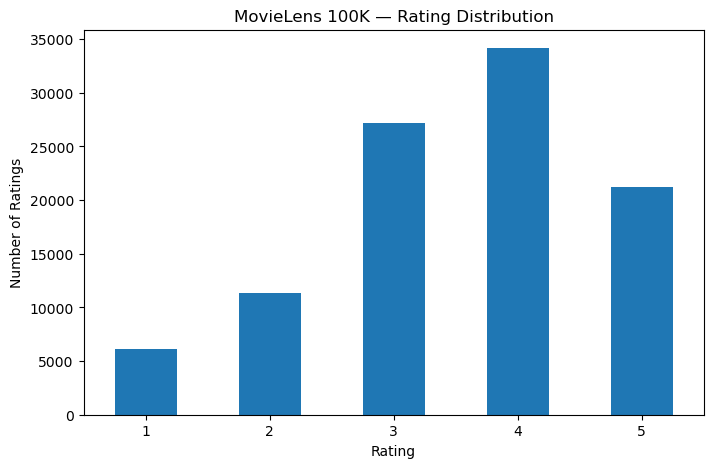

In [6]:
import matplotlib.pyplot as plt

rating_counts = ratings["rating"].value_counts().sort_index()

display(rating_counts)

rating_counts.plot(kind="bar", figsize=(8, 5))

plt.title("MovieLens 100K — Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.show()

### Interpretation — Rating Distribution

The MovieLens 100K dataset contains 100,000 ratings, with scores ranging from 1 to 5.

Rating 4 is the most frequent score, appearing 34,174 times (34.17%), followed by rating 3 with 27,145 occurrences (27.15%). Ratings of 4 and 5 together account for 55.38% of all observations.

**Observation:** The distribution is concentrated toward higher ratings, suggesting that users in this dataset tended to give relatively positive scores.

**Data quality check:** The total number of ratings matches the expected 100,000 observations.

### Ratings per User

**Objective:** Examine how many ratings each user contributed to the MovieLens 100K dataset.

We will group ratings by `user_id`, count the number of ratings per user, and visualize the distribution using a histogram.

This analysis helps us understand differences in user activity and provides a basis for validating the dataset's claim that every user has rated at least 20 movies.

In [7]:
ratings_per_user = ratings.groupby("user_id").size()

display(ratings_per_user.describe())

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64

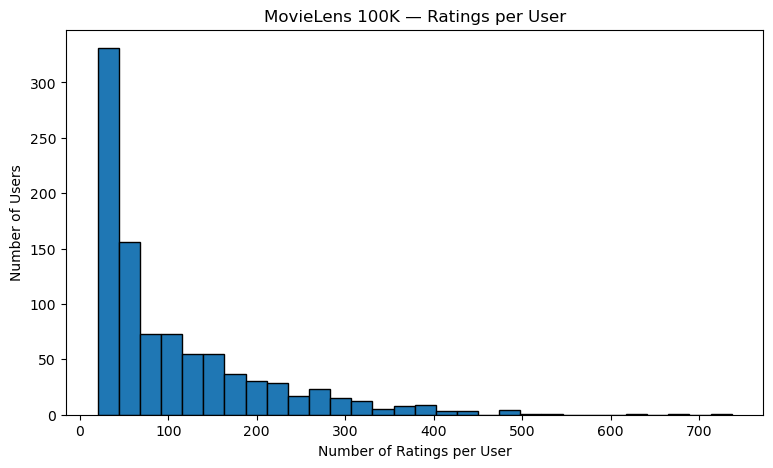

In [9]:
plt.figure(figsize=(9, 5))

plt.hist(
    ratings_per_user,
    bins=30,
    edgecolor="black"
)

plt.title("MovieLens 100K — Ratings per User")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")

plt.show()

### Interpretation — Ratings per User

The dataset contains 943 users, with an average of 106.04 ratings per user and a median of 65 ratings.

The histogram shows a **right-skewed distribution**, with most users contributing relatively few ratings and a small number of highly active users contributing hundreds of ratings.

The minimum number of ratings per user is 20, while the maximum is 737.

**Observation:** The mean is substantially higher than the median because highly active users pull the average upward.

**Data validation:** The minimum of 20 ratings is consistent with the MovieLens 100K dataset's claim that every user has rated at least 20 movies.

### Tidy Data Assessment — Ratings

The `u.data` file follows the basic principles of tidy data. Each row represents one user–movie rating observation, and each column represents a separate variable: `user_id`, `movie_id`, `rating`, and `timestamp`.

The dataset uses a tab delimiter and does not include a header row.

The `timestamp` field is stored as a Unix timestamp and can be converted into a readable date for time-based analysis.

### Tidy Data Assessment — Users and Movies

**Users (`u.user`)**

The `u.user` dataset follows tidy data principles. Each row represents one user, and each column represents a separate attribute, including age, gender, occupation, and ZIP code.

ZIP codes should be stored as text rather than numeric values because they are identifiers and may contain leading zeros.

**Movies (`u.item`)**

The `u.item` dataset contains 1,682 movies and 24 columns. Each row represents one movie, and the final 19 columns are binary genre indicators.

Although the genre indicators can be useful for analysis, they represent a many-to-many relationship between movies and genres.

For relational database design, we will normalize these indicators into separate `genres` and `movie_genres` tables. This allows each movie to be associated with multiple genres without requiring a separate column for every genre.

**Conclusion:** The raw datasets are generally suitable for analysis, but some fields require careful treatment when designing the SQLite database, particularly ZIP codes, missing metadata, and movie genres.